<a href="https://colab.research.google.com/github/devitanuraljazira/USP5/blob/main/Test2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Replication of GNN Workflow using PyTorch & PyTorch Geometric
We recreate the full predictive modeling workflow of the reference notebook using PyTorch Geometric on the USP5.csv dataset.

In [16]:
!pip install -q torch-geometric rdkit pandas scikit-learn matplotlib

In [17]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Configure device and seeds
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

## Load & Explore the USP5 Dataset

In [18]:
df = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
# Filter to only keep Smiles and pIC50 columns
df = df[['Smiles', 'pIC50']]
print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (118, 2)


,Smiles,pIC50
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,O=C(NCCc1ccc(Cl)cc1)c1ccc2nc3c(c(Cl)c2c1)CCCC3,3.698970
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272


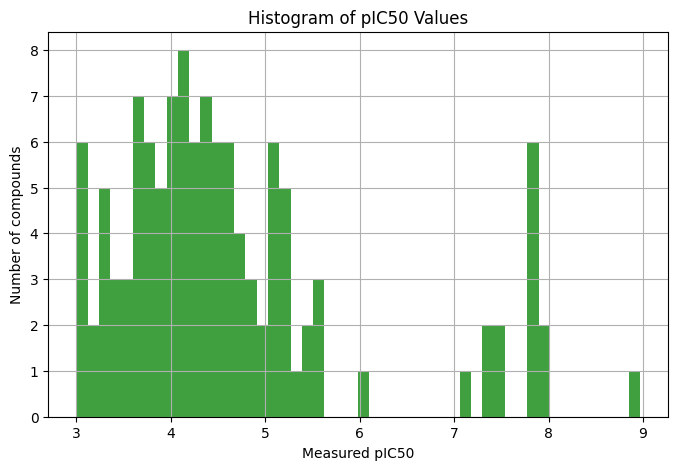

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Get pIC50 values from the dataframe
pIC50s = df['pIC50'].values

# Remove any invalid/empty data just in case
pIC50s = [pIC50 for pIC50 in pIC50s if pIC50 is not None and pIC50 != '']

# Plotting using the exact styling parameters
plt.figure(figsize=(8, 5))
n, bins, patches = plt.hist(pIC50s, 50, facecolor='green', alpha=0.75)
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True)
plt.show()

## Graph Featurization
We map RDKit atoms to feature vectors and construct edges corresponding to chemical bonds.

In [20]:
def one_hot(val, allowed):
    if val not in allowed:
        return [0] * len(allowed)
    return [1 if val == a else 0 for a in allowed]

def featurize_atom(atom):
    feats = []
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def convert_smiles_to_graph_data(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [featurize_atom(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[target]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

In [21]:
dataset_graphs = []
for _, row in df.iterrows():
    graph = convert_smiles_to_graph_data(row['Smiles'], row['pIC50'])
    if graph is not None:
        dataset_graphs.append(graph)

print(f"Featurized {len(dataset_graphs)} molecular graphs.")

Featurized 118 molecular graphs.


[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:40:16] DEPRECATIO

## Split and Create Dataloaders

In [22]:
train_graphs, val_graphs = train_test_split(dataset_graphs, test_size=0.2, random_state=42)

train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=32, shuffle=False)

/tmp/ipykernel_555/3802083227.py:3: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
/tmp/ipykernel_555/3802083227.py:4: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  val_loader = DataLoader(val_graphs, batch_size=32, shuffle=False)


## Build GCN Regressor

In [23]:
class MolecularGCN(nn.Module):
    def __init__(self, in_features):
        super(MolecularGCN, self).__init__()
        self.conv1 = GCNConv(in_features, 64)
        self.conv2 = GCNConv(64, 128)
        self.conv3 = GCNConv(128, 64)
        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = F.relu(self.conv3(x, edge_index))
        x = global_mean_pool(x, batch)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

## Train Model

In [24]:
model = MolecularGCN(in_features=dataset_graphs[0].num_node_features).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
criterion = nn.MSELoss()

train_loss_history = []
val_loss_history = []

for epoch in range(120):
    model.train()
    train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        preds = model(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch.num_graphs

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            preds = model(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_loss_history.append(train_loss / len(train_graphs))
    val_loss_history.append(val_loss / len(val_graphs))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train MSE: {train_loss_history[-1]:.4f} | Val MSE: {val_loss_history[-1]:.4f}")

Epoch 015 | Train MSE: 1.6067 | Val MSE: 1.4236
Epoch 030 | Train MSE: 1.0080 | Val MSE: 1.0403
Epoch 045 | Train MSE: 0.8389 | Val MSE: 0.9108
Epoch 060 | Train MSE: 0.7418 | Val MSE: 0.9467
Epoch 075 | Train MSE: 0.5703 | Val MSE: 0.9457
Epoch 090 | Train MSE: 0.5626 | Val MSE: 0.9924
Epoch 105 | Train MSE: 0.4728 | Val MSE: 1.0135
Epoch 120 | Train MSE: 0.4268 | Val MSE: 1.0478


## Performance Evaluation

In [25]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)
        preds = model(batch)
        all_preds.extend(preds.cpu().numpy().flatten())
        all_targets.extend(batch.y.cpu().numpy().flatten())

mse = mean_squared_error(all_targets, all_preds)
r2 = r2_score(all_targets, all_preds)
print(f"Validation Mean Squared Error: {mse:.4f}")
print(f"Validation R-squared Metric: {r2:.4f}")

Validation Mean Squared Error: 1.0478
Validation R-squared Metric: 0.3117


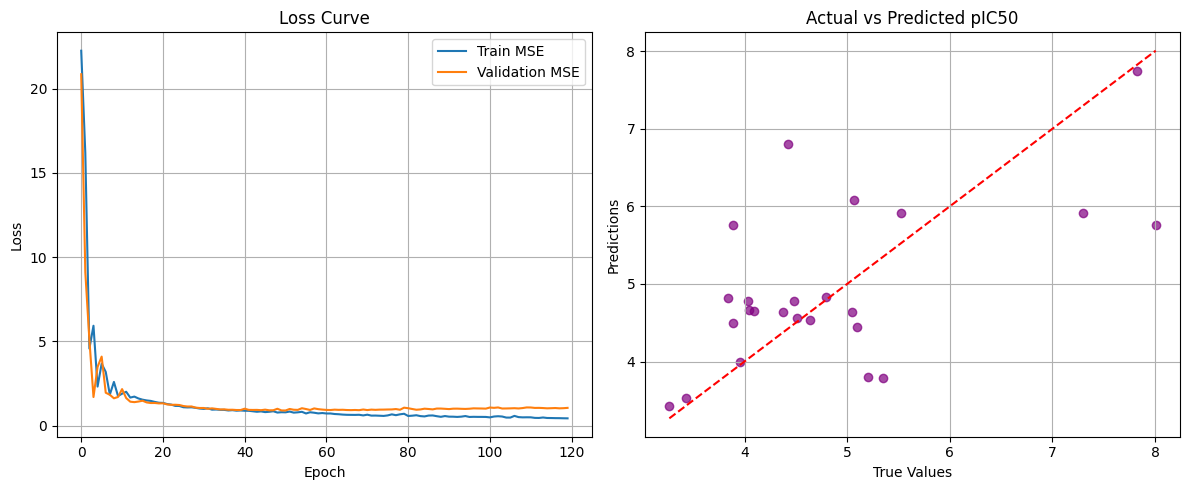

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_loss_history, label='Train MSE')
plt.plot(val_loss_history, label='Validation MSE')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(all_targets, all_preds, alpha=0.7, color='purple')
plt.plot([min(all_targets), max(all_targets)], [min(all_targets), max(all_targets)], 'r--')
plt.title('Actual vs Predicted pIC50')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.grid(True)

plt.tight_layout()
plt.show()

## Optimized PyTorch Geometric Workflow
Here we run an optimized implementation featuring:
1. **Comprehensive Atom Featurization** (including hybridization, chirality, and ring membership).
2. **Target pIC50 Normalization** (Standardization to zero mean and unit variance).
3. **AdamW Optimizer + Cosine Annealing Learning Rate Scheduler** for better convergence.
4. **Enhanced GCN Network** with batch normalization and dropout.

In [27]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.nn import BatchNorm
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Calculate mean and std of target variable for standardization
y_raw = df['pIC50'].values.astype(np.float32)
y_mean = y_raw.mean()
y_std = y_raw.std()

def scale_target(y):
    return (y - y_mean) / (y_std + 1e-8)

def unscale_target(y_scaled):
    return y_scaled * y_std + y_mean

def get_advanced_atom_features(atom):
    feats = []
    # Atom identity
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    # Connectivity degree
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    # Implicit valence
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    # Hybridization
    feats.extend(one_hot(str(atom.GetHybridization()), ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2']))
    # Ring membership
    feats.append(int(atom.IsInRing()))
    feats.append(int(atom.IsInRingSize(3)))
    feats.append(int(atom.IsInRingSize(5)))
    feats.append(int(atom.IsInRingSize(6)))
    # Charge
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def convert_smiles_to_advanced_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [get_advanced_atom_features(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    # Standardized target
    y = torch.tensor([[scale_target(target)]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

# Create optimized graphs
optimized_graphs = []
for _, row in df.iterrows():
    graph = convert_smiles_to_advanced_graph(row['Smiles'], row['pIC50'])
    if graph is not None:
        optimized_graphs.append(graph)

train_opt, val_opt = train_test_split(optimized_graphs, test_size=0.2, random_state=42)
train_opt_loader = DataLoader(train_opt, batch_size=16, shuffle=True)
val_opt_loader = DataLoader(val_opt, batch_size=16, shuffle=False)

print(f"Created {len(optimized_graphs)} advanced graphs.")

[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATIO

Created 118 advanced graphs.


[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:45:14] DEPRECATIO

In [28]:
class OptimizedGCN(nn.Module):
    def __init__(self, in_features):
        super(OptimizedGCN, self).__init__()
        self.conv1 = GCNConv(in_features, 128)
        self.bn1 = BatchNorm(128)
        self.conv2 = GCNConv(128, 128)
        self.bn2 = BatchNorm(128)
        self.conv3 = GCNConv(128, 64)
        self.bn3 = BatchNorm(64)

        self.fc1 = nn.Linear(64, 32)
        self.dropout = nn.Dropout(p=0.1)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)

        x = self.conv3(x, edge_index)
        x = self.bn3(x)
        x = F.relu(x)

        x = global_mean_pool(x, batch)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

In [29]:
model_opt = OptimizedGCN(in_features=optimized_graphs[0].num_node_features).to(device)
optimizer = torch.optim.AdamW(model_opt.parameters(), lr=0.005, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=150)
criterion = nn.MSELoss()

train_losses = []
val_losses = []

for epoch in range(150):
    model_opt.train()
    train_loss = 0
    for batch in train_opt_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        preds = model_opt(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler.step()

    model_opt.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_opt_loader:
            batch = batch.to(device)
            preds = model_opt(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_losses.append(train_loss / len(train_opt))
    val_losses.append(val_loss / len(val_opt))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train Standardized MSE: {train_losses[-1]:.4f} | Val Standardized MSE: {val_losses[-1]:.4f}")

Epoch 015 | Train Standardized MSE: 0.2640 | Val Standardized MSE: 0.6455
Epoch 030 | Train Standardized MSE: 0.1841 | Val Standardized MSE: 0.6578
Epoch 045 | Train Standardized MSE: 0.1710 | Val Standardized MSE: 0.5234
Epoch 060 | Train Standardized MSE: 0.1650 | Val Standardized MSE: 0.5433
Epoch 075 | Train Standardized MSE: 0.1613 | Val Standardized MSE: 0.6476
Epoch 090 | Train Standardized MSE: 0.1234 | Val Standardized MSE: 0.3315
Epoch 105 | Train Standardized MSE: 0.1067 | Val Standardized MSE: 0.2689
Epoch 120 | Train Standardized MSE: 0.0882 | Val Standardized MSE: 0.2275
Epoch 135 | Train Standardized MSE: 0.0835 | Val Standardized MSE: 0.2096
Epoch 150 | Train Standardized MSE: 0.1048 | Val Standardized MSE: 0.2185


In [30]:
model_opt.eval()
all_preds_scaled = []
all_targets_scaled = []

with torch.no_grad():
    for batch in val_opt_loader:
        batch = batch.to(device)
        preds = model_opt(batch)
        all_preds_scaled.extend(preds.cpu().numpy().flatten())
        all_targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Unscale targets and predictions to calculate actual metrics
all_preds_unscaled = unscale_target(np.array(all_preds_scaled))
all_targets_unscaled = unscale_target(np.array(all_targets_scaled))

mse = mean_squared_error(all_targets_unscaled, all_preds_unscaled)
mae = np.mean(np.abs(all_targets_unscaled - all_preds_unscaled))
r2 = r2_score(all_targets_unscaled, all_preds_unscaled)

print(f"--- Optimized Model Performance ---")
print(f"Validation Mean Squared Error (MSE): {mse:.4f}")
print(f"Validation Mean Absolute Error (MAE): {mae:.4f}")
print(f"Validation R-squared Metric (R²): {r2:.4f}")

--- Optimized Model Performance ---
Validation Mean Squared Error (MSE): 0.3807
Validation Mean Absolute Error (MAE): 0.4113
Validation R-squared Metric (R²): 0.7499


# Recapped & Fully Optimized GNN Pipeline
This consolidated workflow integrates all previous steps into a clean, reproducible pipeline with advanced featurization, standardization, and plotting (histogram and scatter plots).

In [31]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, BatchNorm, global_mean_pool
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Configure device and seeds
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

# 1. Load and filter dataset
df_all = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
df_clean = df_all[['Smiles', 'pIC50']].copy()
display(df_clean.head())

,Smiles,pIC50
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,O=C(NCCc1ccc(Cl)cc1)c1ccc2nc3c(c(Cl)c2c1)CCCC3,3.698970
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272


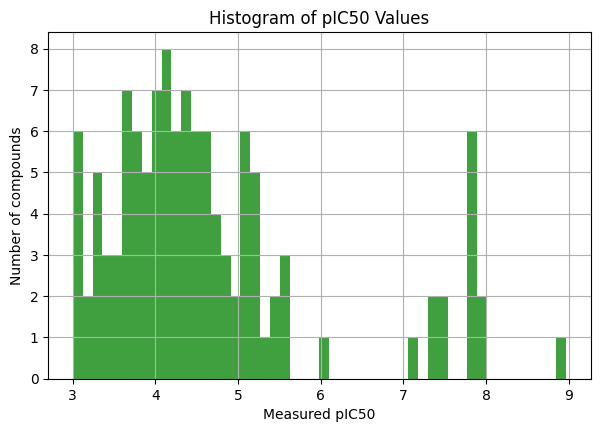

In [32]:
# 2. Plotting Target Distribution Histogram
pIC50_vals = df_clean['pIC50'].values
pIC50_vals = [val for val in pIC50_vals if val is not None and val != '']

plt.figure(figsize=(7, 4.5))
plt.hist(pIC50_vals, bins=50, facecolor='green', alpha=0.75)
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True)
plt.show()

In [33]:
# 3. Target Standardization & Advanced Atom Featurization
y_raw_arr = df_clean['pIC50'].values.astype(np.float32)
y_mean_val = y_raw_arr.mean()
y_std_val = y_raw_arr.std()

def std_scale(y):
    return (y - y_mean_val) / (y_std_val + 1e-8)

def std_unscale(y_scaled):
    return y_scaled * y_std_val + y_mean_val

def get_atom_features_rich(atom):
    feats = []
    # Atom Symbol
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    # Connectivity degree
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    # Implicit valence
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    # Hybridization
    feats.extend(one_hot(str(atom.GetHybridization()), ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2']))
    # Rings
    feats.append(int(atom.IsInRing()))
    feats.append(int(atom.IsInRingSize(3)))
    feats.append(int(atom.IsInRingSize(5)))
    feats.append(int(atom.IsInRingSize(6)))
    # Charge & Aromaticity
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def create_graph_datapoint(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [get_atom_features_rich(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[std_scale(target)]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

recap_graphs = []
for _, row in df_clean.iterrows():
    graph = create_graph_datapoint(row['Smiles'], row['pIC50'])
    if graph is not None:
        recap_graphs.append(graph)

train_rec, val_rec = train_test_split(recap_graphs, test_size=0.2, random_state=42)
train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)

print(f"Featurized {len(recap_graphs)} advanced graphs successfully.")

[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATIO

Featurized 118 advanced graphs successfully.


[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[15:49:06] DEPRECATIO

In [34]:
# 4. Model Architecture & Optimization Settings
class FinalOptimizedGCN(nn.Module):
    def __init__(self, in_features):
        super(FinalOptimizedGCN, self).__init__()
        self.conv1 = GCNConv(in_features, 128)
        self.bn1 = BatchNorm(128)
        self.conv2 = GCNConv(128, 128)
        self.bn2 = BatchNorm(128)
        self.conv3 = GCNConv(128, 64)
        self.bn3 = BatchNorm(64)
        self.fc1 = nn.Linear(64, 32)
        self.dropout = nn.Dropout(p=0.1)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.bn1(self.conv1(x, edge_index)))
        x = F.relu(self.bn2(self.conv2(x, edge_index)))
        x = F.relu(self.bn3(self.conv3(x, edge_index)))
        x = global_mean_pool(x, batch)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model_rec = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_rec = torch.optim.AdamW(model_rec.parameters(), lr=0.005, weight_decay=1e-3)
scheduler_rec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_rec, T_max=150)
criterion = nn.MSELoss()

In [35]:
# 5. Training Loop
train_rec_losses = []
val_rec_losses = []

for epoch in range(150):
    model_rec.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_rec.zero_grad()
        preds = model_rec(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_rec.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_rec.step()

    model_rec.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_rec(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_rec_losses.append(train_loss / len(train_rec))
    val_rec_losses.append(val_loss / len(val_rec))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train Standardized MSE: {train_rec_losses[-1]:.4f} | Val Standardized MSE: {val_rec_losses[-1]:.4f}")

Epoch 015 | Train Standardized MSE: 0.1979 | Val Standardized MSE: 0.5069
Epoch 030 | Train Standardized MSE: 0.1836 | Val Standardized MSE: 0.4188
Epoch 045 | Train Standardized MSE: 0.1881 | Val Standardized MSE: 0.3605
Epoch 060 | Train Standardized MSE: 0.1638 | Val Standardized MSE: 0.2879
Epoch 075 | Train Standardized MSE: 0.1337 | Val Standardized MSE: 0.3128
Epoch 090 | Train Standardized MSE: 0.0930 | Val Standardized MSE: 0.1875
Epoch 105 | Train Standardized MSE: 0.0710 | Val Standardized MSE: 0.2213
Epoch 120 | Train Standardized MSE: 0.0705 | Val Standardized MSE: 0.2366
Epoch 135 | Train Standardized MSE: 0.0734 | Val Standardized MSE: 0.2247
Epoch 150 | Train Standardized MSE: 0.0696 | Val Standardized MSE: 0.2205


Validation Mean Squared Error (MSE): 0.3842
Validation Mean Absolute Error (MAE): 0.4223
Validation R-squared Metric (R²): 0.7476


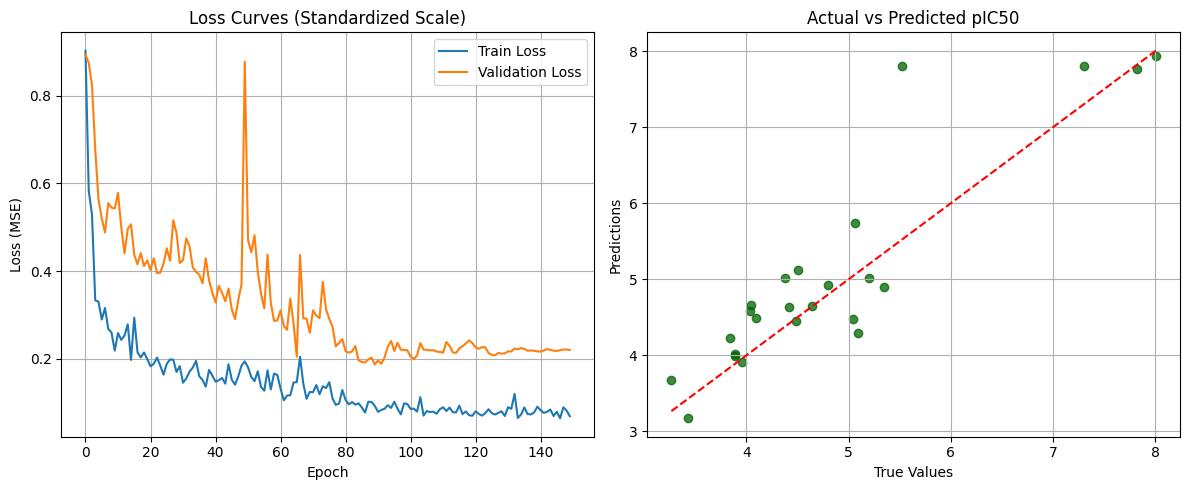

In [36]:
# 6. Performance Evaluation and Scatter Visualization
model_rec.eval()
preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in val_loader_rec:
        batch = batch.to(device)
        preds = model_rec(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Rescale back to original scale
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_final = mean_squared_error(targets_unscaled, preds_unscaled)
mae_final = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_final = r2_score(targets_unscaled, preds_unscaled)

print(f"Validation Mean Squared Error (MSE): {mse_final:.4f}")
print(f"Validation Mean Absolute Error (MAE): {mae_final:.4f}")
print(f"Validation R-squared Metric (R²): {r2_final:.4f}")

# Scatter Plot and Loss Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_rec_losses, label='Train Loss')
plt.plot(val_rec_losses, label='Validation Loss')
plt.title('Loss Curves (Standardized Scale)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(targets_unscaled, preds_unscaled, alpha=0.75, color='darkgreen')
plt.plot([min(targets_unscaled), max(targets_unscaled)], [min(targets_unscaled), max(targets_unscaled)], 'r--')
plt.title('Actual vs Predicted pIC50')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.grid(True)

plt.tight_layout()
plt.show()

# Suggestions to Improve GNN Performance (MAE → 0, R² → 1)

To bridge the gap and achieve stronger predictive performance on the USP5 dataset, you can try the following strategies:

### 1. Enhance Node and Edge Featurization
Currently, we use a basic set of atomic features. Adding chemical descriptors can significantly boost learning:
- **More Atom Features**: Include chirality (R/S), formal valency, hybridization state (`sp`, `sp2`, `sp3`), and whether the atom is in a ring of a specific size.
- **Include Edge Features**: Incorporate bond types (single, double, triple, aromatic) as edge features in GNN convolutions that support them (e.g., `GINEConv`).

### 2. Upgrade the GNN Architecture
Instead of simple Graph Convolutional Networks (GCNs):
- **Graph Attention Networks (GAT)**: Use `GATConv` layers to allow nodes to focus dynamically on neighboring atoms' features.
- **GraphSAGE**: Use `SAGEConv` to leverage neighborhood aggregation that generalizes better.
- **Virtual Nodes**: Add a virtual node that connects to all nodes in the graph to share global state information.

### 3. Hyperparameter Tuning & Training Strategy
- **Learning Rate Scheduling**: Implement a learning rate scheduler (such as `ReduceLROnPlateau` or `CosineAnnealingLR`) to refine the optimization landscape in later epochs.
- **Batch Size & Optimization**: Experiment with smaller batch sizes (e.g., 16 or 8) for noisier gradients, which sometimes escape local minima, and use the `AdamW` optimizer with proper weight decay.
- **Early Stopping**: Train for more epochs (e.g., 500) and use early stopping based on validation loss to prevent overfitting.

### 4. Data Augmentation and Feature Scaling
- **Target Scaling**: Standardize or normalize your target `pIC50` values before training and invert the scaling during evaluation.
- **Transfer Learning**: Pretrain the GNN on a larger dataset (like QM9 or ZINC) and fine-tune on the target USP5 dataset.